In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [22]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [23]:
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [24]:
# TotalCharges contains blank strings, so it was read as text
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values:", df["TotalCharges"].isna().sum())

# Only 11 rows are affected (new customers), so we drop them
df = df.dropna()

# customerID is just an identifier, not useful for prediction
df = df.drop("customerID", axis=1)

# Convert the target to numbers: Yes = 1, No = 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(df.shape)
df.head()

Missing values: 11
(7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


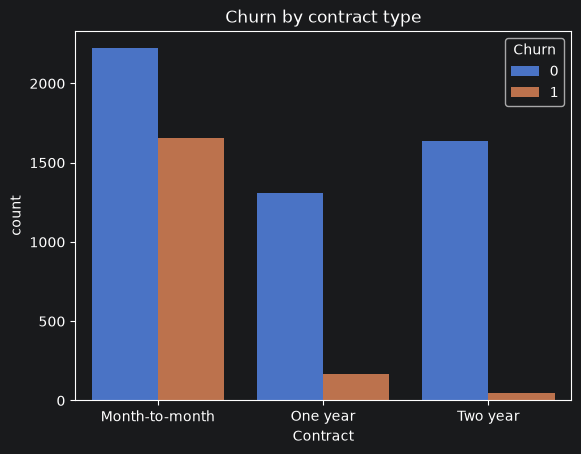

In [25]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by contract type")
plt.show()

In [26]:
(df.groupby("Contract")["Churn"].mean() * 100).round(1)

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

Each value is the percentage of customers who left in that contract type. For example, 42.7 means 42.7% churned.

**Observation:** Churn depends strongly on contract type. Month-to-month customers churn at about **42.7%**, compared with about **11.3%** for one-year contracts and **2.8%** for two-year contracts.

**Business meaning:** Longer contracts are associated with much lower churn. The company should encourage month-to-month customers to switch to annual contracts, for example with a discount or a free add-on.

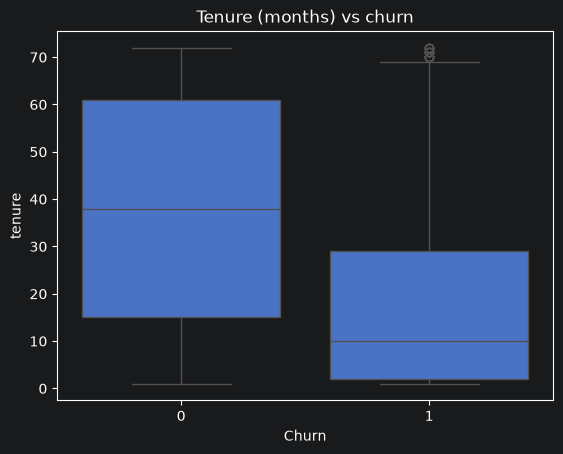

In [27]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure (months) vs churn")
plt.show()

In [28]:
df.groupby("Churn")["tenure"].agg(["mean", "median", "min", "max"]).round(1)

,mean,median,min,max
Churn,,,,
0,37.7,38.0,1,72
1,18.0,10.0,1,72


**Observation:** Customers who churn have a much shorter tenure. The median churner stayed about **10 months**, while the median customer who stayed has a tenure of about **38 months**.

**Business meaning:** The first year is the highest-risk period. Better onboarding, early check-in calls and welcome offers could reduce early churn.

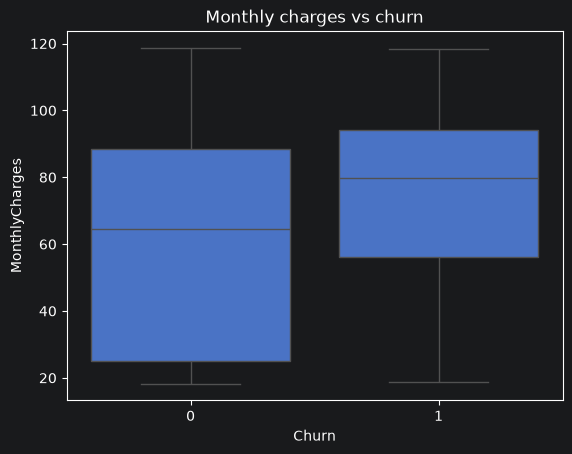

In [29]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges vs churn")
plt.show()

In [30]:
df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median", "min", "max"]).round(1)

,mean,median,min,max
Churn,,,,
0,61.3,64.4,18.2,118.8
1,74.4,79.6,18.8,118.4


**Observation:** Churners pay more on average: about **74** per month, compared with about **61** for customers who stay. The two groups overlap, so price alone does not explain churn.

**Business meaning:** Customers with higher bills may feel they are not getting enough value. Targeted discounts or better service for high-paying customers could help retain them.

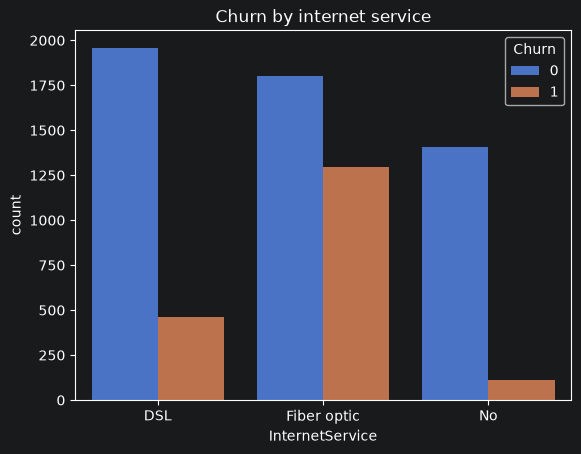

In [31]:
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Churn by internet service")
plt.show()

In [32]:
(df.groupby("InternetService")["Churn"].mean() * 100).round(1)

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64

**Observation:** Fiber optic customers churn at about **41.9%**, more than double the rate of DSL customers (about **19.0%**). Customers with no internet service churn the least (about **7.4%**).

**Business meaning:** Fiber is usually the more expensive product, so the high churn may point to pricing or service-quality problems. The company should investigate the fiber optic customer experience.

In [33]:
summary = df.groupby("Contract")["Churn"].agg(["count", "mean"])
summary["churn_rate_%"] = (summary["mean"] * 100).round(1)
summary[["count", "churn_rate_%"]]

,count,churn_rate_%
Contract,,
Month-to-month,3875,42.7
One year,1472,11.3
Two year,1685,2.8


**Key takeaways from the exploration**

- Churn is highest among new customers on month-to-month contracts.
- Fiber optic customers and customers with higher monthly charges also churn more.
- These patterns are associations, not proof of cause, and they will guide the modeling in the next section.

In [34]:
from sklearn.model_selection import train_test_split

# Convert text columns (Contract, InternetService, ...) into 0/1 columns
X = pd.get_dummies(df.drop("Churn", axis=1), drop_first=True)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X.shape)
print("Train:", X_train.shape, "Test:", X_test.shape)

(7032, 30)
Train: (5625, 30) Test: (1407, 30)


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Baseline: a simple, easy-to-explain model
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr.fit(X_train, y_train)

# Stronger model: many decision trees voting together
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42)
rf.fit(X_train, y_train)

print("Both models trained")

Both models trained


In [36]:
from sklearn.metrics import classification_report, roc_auc_score

for name, model in [("Logistic Regression", lr), ("Random Forest", rf)]:
    pred = model.predict(X_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print("=====", name, "| ROC-AUC:", round(auc, 3))
    print(classification_report(y_test, pred))

===== Logistic Regression | ROC-AUC: 0.836
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

===== Random Forest | ROC-AUC: 0.821
              precision    recall  f1-score   support

           0       0.87      0.81      0.84      1033
           1       0.56      0.66      0.61       374

    accuracy                           0.77      1407
   macro avg       0.72      0.74      0.72      1407
weighted avg       0.79      0.77      0.78      1407



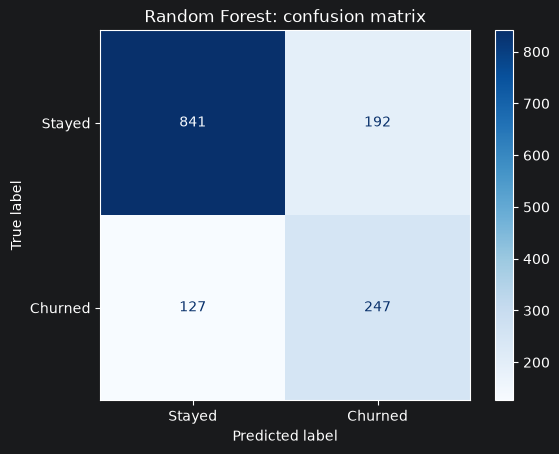

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rf, X_test, y_test, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Random Forest: confusion matrix")
plt.show()

In [38]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "ROC-AUC": [
        roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])]
}).round(3)
results

,Model,ROC-AUC
0,Logistic Regression,0.836
1,Random Forest,0.821


**Model comparison**

Accuracy alone is misleading here, because 73% of customers do not churn. I evaluated the models using ROC-AUC and recall for churners (class 1) on a test set of 1,407 customers, 374 of whom churned.

| Model | ROC-AUC | Churn recall | Churn precision | Churn F1 | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression | 0.836 | 0.57 | 0.65 | 0.61 | 0.80 |
| Random Forest | 0.821 | 0.66 | 0.56 | 0.61 | 0.77 |

**Trade-off:** Logistic Regression has the better ROC-AUC and precision, so its warnings are more often correct. The Random Forest catches more real churners: recall of 0.66 vs 0.57, which is roughly 34 more of the 374 churners found. Its cost is lower precision, meaning more loyal customers get flagged by mistake. The F1 score is the same for both (0.61).

**Decision:** I chose the Random Forest as the final model. In a retention setting, missing a customer who leaves is more expensive than sending a discount to someone who would have stayed, so higher recall is the priority. It also works directly with SHAP's TreeExplainer, which lets me explain each prediction in the next section.

**Limitations:** The ROC-AUC gap is small, which suggests the patterns in this data are mostly linear, so Logistic Regression remains a strong, simple baseline. Both models use the default 0.5 probability threshold. A company could lower the threshold to catch even more churners, at the cost of more false alarms.

In [39]:
import joblib

joblib.dump(rf, "../model.pkl")
joblib.dump(list(X.columns), "../columns.pkl")
print("Saved")

Saved


In [40]:
import shap

# Use a sample of 500 test customers to keep it fast
X_sample = X_test.sample(500, random_state=42)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_sample)

# Different shap versions return different formats; this handles all of them
if isinstance(shap_values, list):
    sv = shap_values[1]
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

ev = explainer.expected_value
base_value = ev[1] if hasattr(ev, "__len__") else ev

print("SHAP values shape:", sv.shape)

SHAP values shape: (500, 30)


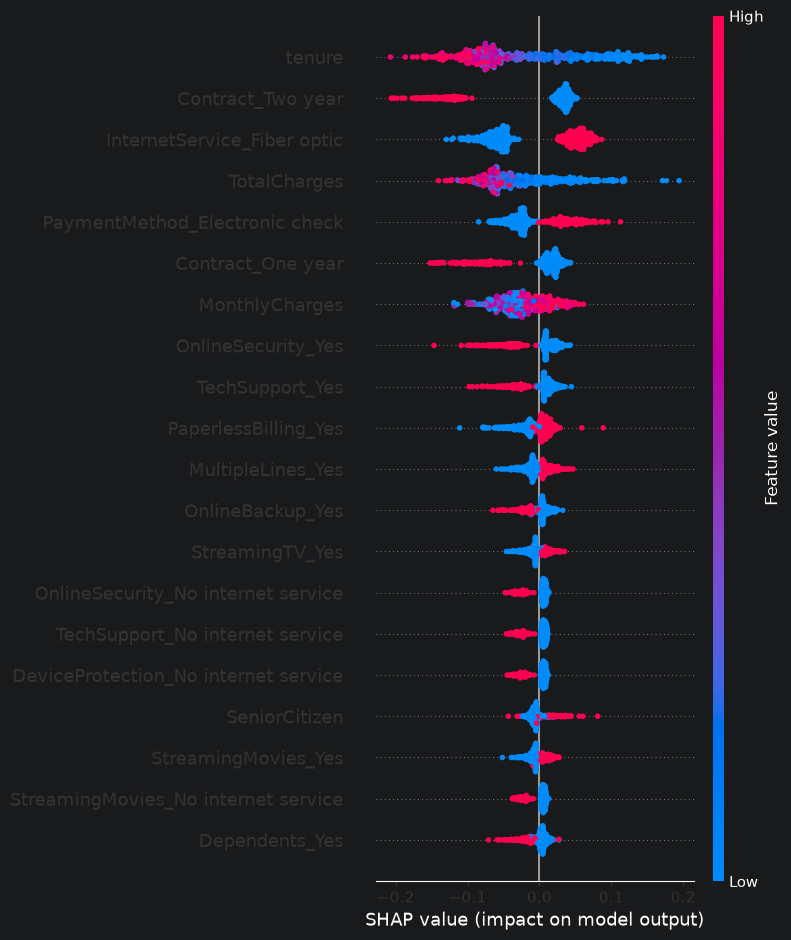

In [44]:
shap.summary_plot(sv, X_sample, show=False)
plt.tight_layout()
plt.savefig("../images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

**What drives churn (SHAP analysis)**

The SHAP summary plot ranks the features by their impact on the predicted churn risk. Each dot is a customer; dots to the right increase the risk and dots to the left lower it.

- **Tenure** is the strongest driver. Short-tenure customers have a higher predicted risk and long-tenure customers a much lower one.
- **Contract type** is next. Two-year and one-year contracts strongly reduce the risk compared with month-to-month contracts.
- **Fiber optic internet** increases the predicted risk, which matches the exploration earlier.
- **Total charges** has a similar pattern to tenure (low total charges means higher risk), mostly because customers who stay longer accumulate higher totals.
- **Electronic check payment** and **paperless billing** are associated with higher risk.
- **Online security** and **tech support** are associated with lower risk, which suggests that customers using support services are more engaged.
- **Monthly charges** has a mixed and weaker effect: higher charges tilt slightly toward higher risk, but the pattern is less clear.

These are associations in the data, not proven causes.

In [42]:
plt.savefig("../images/shap_summary.png", dpi=150, bbox_inches="tight", facecolor="white")

<Figure size 640x480 with 0 Axes>

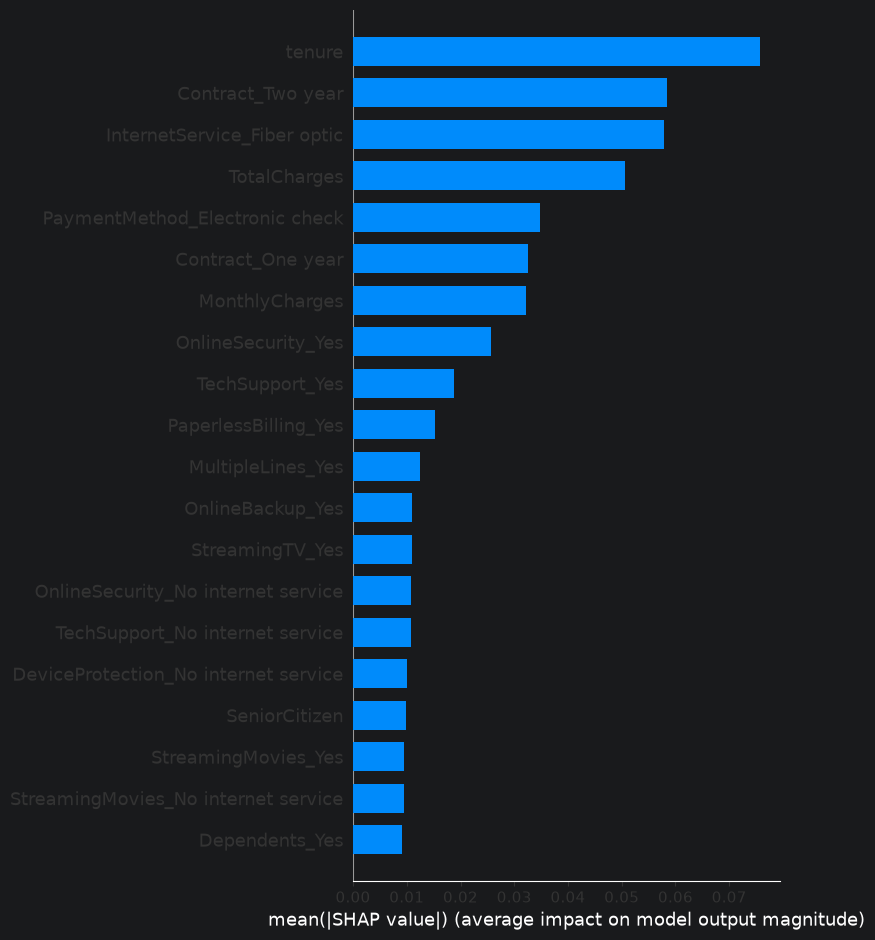

In [45]:
shap.summary_plot(sv, X_sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("../images/shap_bar.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

**Global feature importance (mean absolute SHAP value)**

The bar chart ranks the features by their average impact on the model's churn risk score, across the 500 customers in the sample. A longer bar means the feature moves predictions more. It shows the size of the effect, not the direction (the summary plot above shows the direction).

- **Tenure** is the most important feature (about 0.076), ahead of every other variable.
- **Contract type** comes next: the two-year contract (about 0.058) and the one-year contract (about 0.033) both rank in the top 7.
- **Fiber optic internet** (about 0.058) is the third strongest factor.
- **Total charges** (about 0.05) ranks fourth, but it is closely linked to tenure, because customers who stay longer accumulate higher totals.
- **Electronic check payment** (about 0.035) and **monthly charges** (about 0.032) are the next most important.
- **Online security** (about 0.026) and **tech support** (about 0.019) are the most influential add-on services.
- The remaining features, such as streaming services, dependents and senior citizen status, have a much smaller impact (about 0.01 each).

**Takeaway:** Customer lifecycle and contract features (tenure, contract type, total charges) matter most, followed by the type of internet service and payment method. Together they point to new, month-to-month customers as the group to target first. The "No internet service" features are all different ways of encoding the same fact (the customer has no internet), so their small bars should not be read as separate effects.

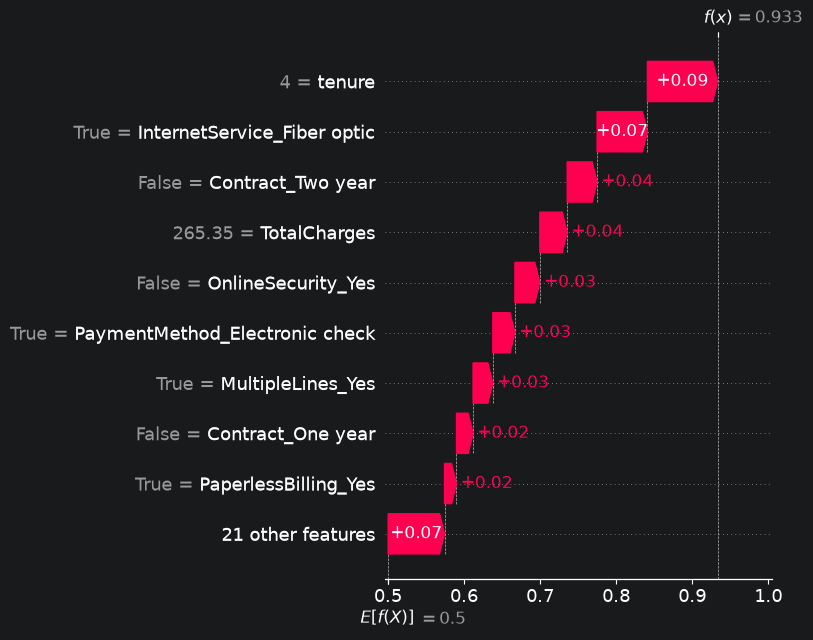

Predicted churn probability: 0.93


In [46]:
i = 0  # change this number to explain a different customer

explanation = shap.Explanation(
    values=sv[i],
    base_values=base_value,
    data=X_sample.iloc[i],
    feature_names=list(X_sample.columns))

shap.plots.waterfall(explanation, show=False)
plt.tight_layout()
plt.savefig("../images/shap_customer.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print("Predicted churn probability:",
      round(rf.predict_proba(X_sample.iloc[[i]])[0][1], 2))

**Explaining one customer**

This customer has a churn risk score of 0.93, compared with an average of 0.50. Every major factor pushes the risk up:

- Very short tenure (4 months)
- Fiber optic internet
- No one-year or two-year contract (month-to-month)
- No online security service
- Payment by electronic check and paperless billing

This is the profile the retention team should contact first: a new month-to-month fiber customer. The waterfall plot lets the team see the reasons behind the score, for example offering a longer-contract discount or a free security add-on.

Note: the model uses balanced class weights, so scores are higher than real-world probabilities. They are best used to rank customers by risk, not as exact percentages.